In [16]:
# Analyse Exploratoire (EDA) - House Prices
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Config globale
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100

# Chemins
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

DATA_PATH = Path("../data/processed/houses_clean.csv")

print("✅ Setup OK")

✅ Setup OK


In [17]:
df = pd.read_csv(DATA_PATH)
print(f"📊 Dataset : {df.shape[0]} lignes × {df.shape[1]} colonnes")
df.head()

📊 Dataset : 1460 lignes × 89 colonnes


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,SaleCondition,SalePrice,HouseAge,RemodAge,TotalSF,TotalBath,PricePerSF,HasGarage,HasPool,HasFireplace
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,Normal,208500,5,5,2566,3.5,81.254871,1,0,0
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,Normal,181500,31,31,2524,2.5,71.909667,1,0,1
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,Normal,223500,7,6,2706,3.5,82.594235,1,0,1
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,Abnorml,140000,91,36,2473,2.0,56.611403,1,0,1
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,Normal,250000,8,8,3343,3.5,74.783129,1,0,1


In [18]:
# Statistiques des variables numériques clés
key_cols = ['SalePrice', 'GrLivArea', 'TotalSF', 'OverallQual', 
            'YearBuilt', 'HouseAge', 'TotalBath', 'GarageArea']
df[key_cols].describe().round(2)

,SalePrice,GrLivArea,TotalSF,OverallQual,YearBuilt,HouseAge,TotalBath,GarageArea
count,1460.0,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00
mean,180921.2,1515.46,2567.05,6.10,1971.27,36.55,2.21,472.98
std,79442.5,525.48,821.71,1.38,30.20,30.25,0.79,213.80
min,34900.0,334.00,334.00,1.00,1872.00,0.00,1.00,0.00
25%,129975.0,1129.50,2009.50,5.00,1954.00,8.00,2.00,334.50
50%,163000.0,1464.00,2474.00,6.00,1973.00,35.00,2.00,480.00
75%,214000.0,1776.75,3004.00,7.00,2000.00,54.00,2.50,576.00
max,755000.0,5642.00,11752.00,10.00,2010.00,136.00,6.00,1418.00


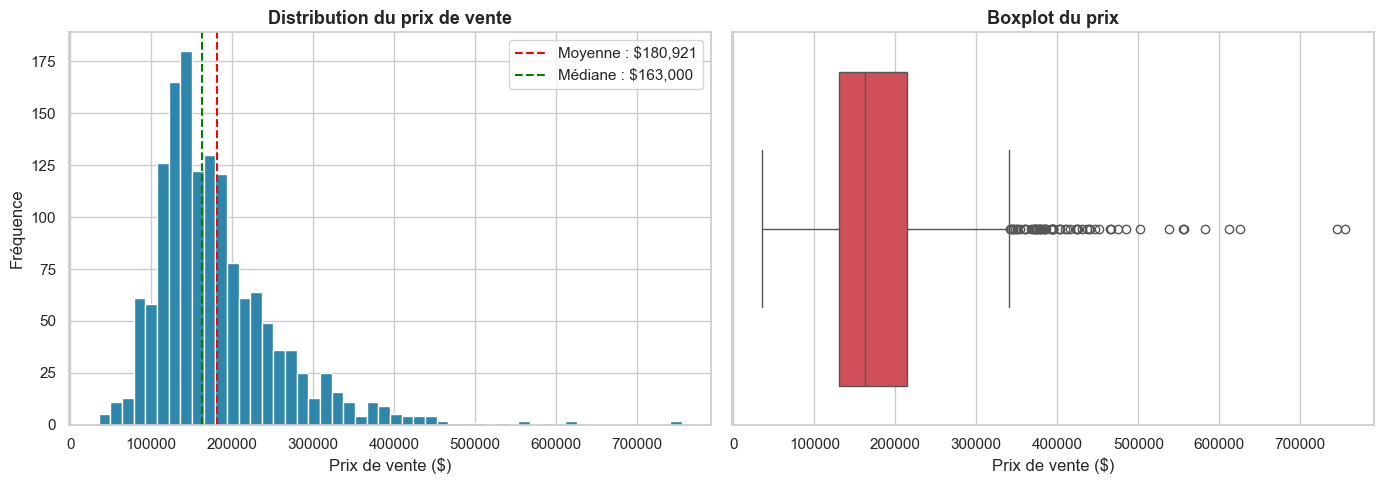

💡 Prix moyen : $180,921
💡 Médiane    : $163,000
💡 Asymétrie  : 1.88 (>0 → étalée vers la droite)


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogramme
axes[0].hist(df['SalePrice'], bins=50, color='#2E86AB', edgecolor='white')
axes[0].axvline(df['SalePrice'].mean(), color='red', linestyle='--', 
                label=f"Moyenne : ${df['SalePrice'].mean():,.0f}")
axes[0].axvline(df['SalePrice'].median(), color='green', linestyle='--', 
                label=f"Médiane : ${df['SalePrice'].median():,.0f}")
axes[0].set_xlabel('Prix de vente ($)')
axes[0].set_ylabel('Fréquence')
axes[0].set_title('Distribution du prix de vente', fontsize=13, fontweight='bold')
axes[0].legend()

# Boxplot
sns.boxplot(x=df['SalePrice'], ax=axes[1], color='#E63946')
axes[1].set_xlabel('Prix de vente ($)')
axes[1].set_title('Boxplot du prix', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig(FIG_DIR / '01_price_distribution.png', bbox_inches='tight')
plt.show()

print(f"💡 Prix moyen : ${df['SalePrice'].mean():,.0f}")
print(f"💡 Médiane    : ${df['SalePrice'].median():,.0f}")
print(f"💡 Asymétrie  : {df['SalePrice'].skew():.2f} (>0 → étalée vers la droite)")

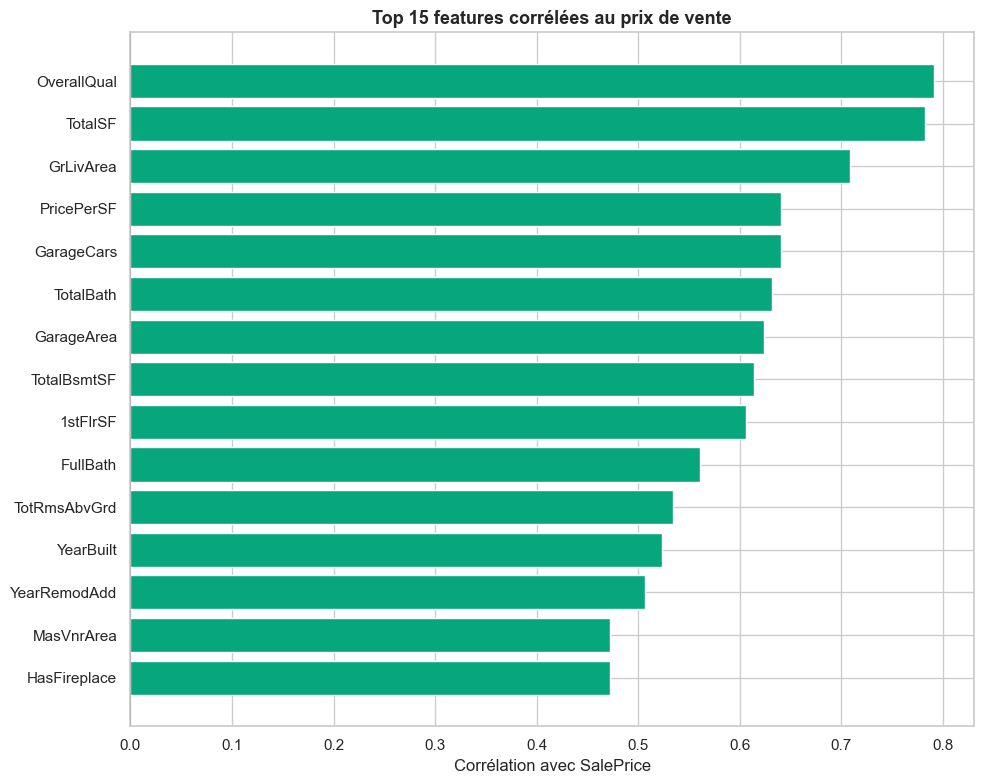


🔝 Top 5 corrélations :
   OverallQual          : +0.791
   TotalSF              : +0.782
   GrLivArea            : +0.709
   PricePerSF           : +0.641
   GarageCars           : +0.640


In [20]:
# Colonnes numériques les plus corrélées au prix
num_cols = df.select_dtypes(include=[np.number]).columns
corr = df[num_cols].corr()['SalePrice'].sort_values(ascending=False)

# Top 15 corrélations
top_corr = corr.head(16).drop('SalePrice')

fig, ax = plt.subplots(figsize=(10, 8))
colors = ['#06A77D' if v > 0 else '#E63946' for v in top_corr.values]
ax.barh(top_corr.index[::-1], top_corr.values[::-1], color=colors[::-1])
ax.set_xlabel('Corrélation avec SalePrice')
ax.set_title('Top 15 features corrélées au prix de vente', 
             fontsize=13, fontweight='bold')
ax.axvline(0, color='black', linewidth=0.5)

plt.tight_layout()
plt.savefig(FIG_DIR / '02_correlation.png', bbox_inches='tight')
plt.show()

print("\n🔝 Top 5 corrélations :")
for col, val in top_corr.head(5).items():
    print(f"   {col:<20} : {val:+.3f}")

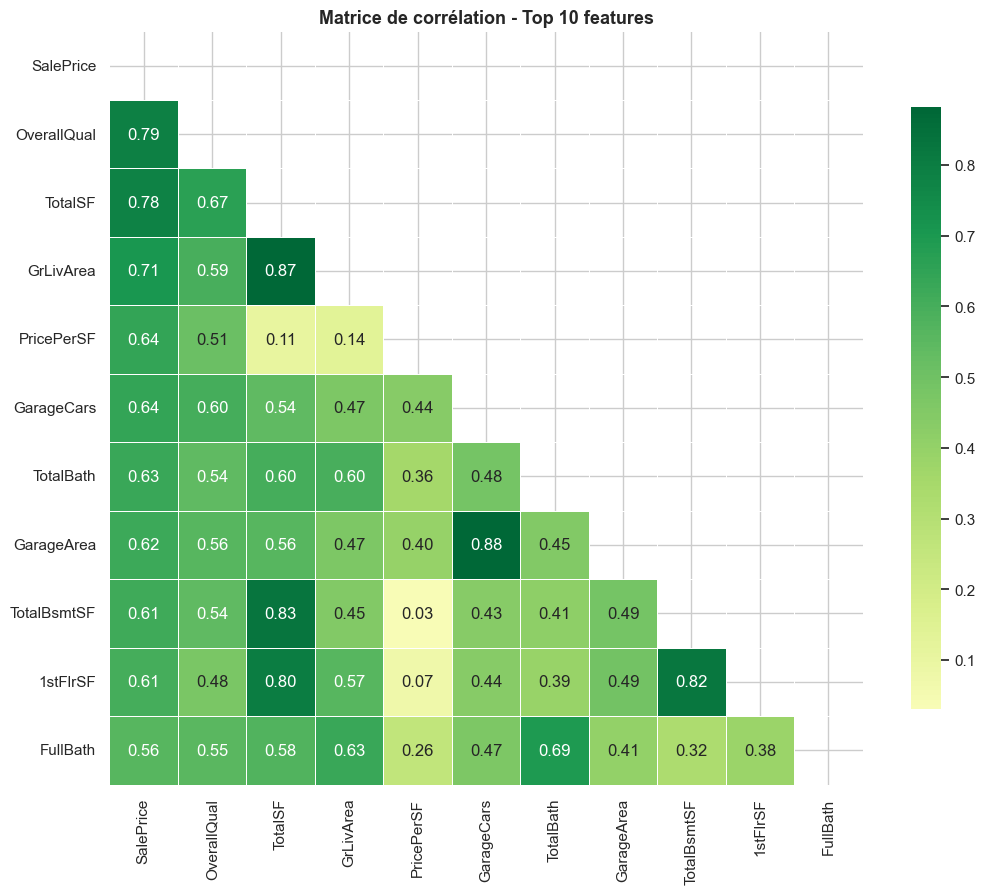

In [21]:
# Heatmap des 10 features les plus corrélées
top_features = corr.head(11).index.tolist()
corr_matrix = df[top_features].corr()

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
            cmap='RdYlGn', center=0, square=True, linewidths=0.5,
            cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title('Matrice de corrélation - Top 10 features',
             fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig(FIG_DIR / '03_heatmap.png', bbox_inches='tight')
plt.show()

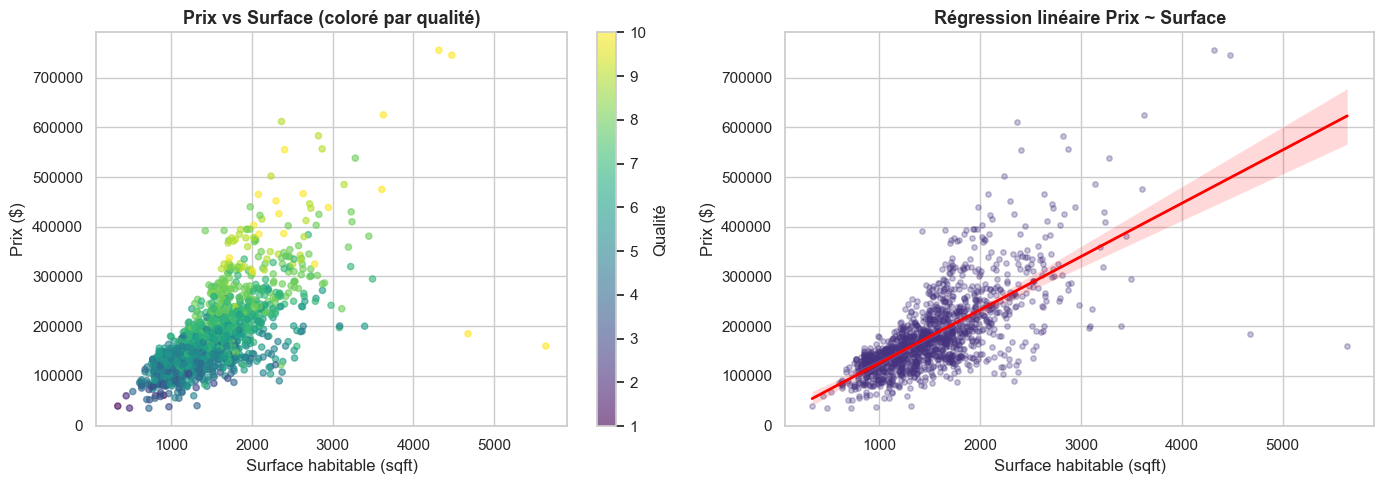

💡 Corrélation Surface ~ Prix : r = 0.709


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter qualité
scatter = axes[0].scatter(df['GrLivArea'], df['SalePrice'],
                          c=df['OverallQual'], cmap='viridis',
                          alpha=0.6, s=20)
axes[0].set_xlabel('Surface habitable (sqft)')
axes[0].set_ylabel('Prix ($)')
axes[0].set_title('Prix vs Surface (coloré par qualité)',
                  fontsize=13, fontweight='bold')
plt.colorbar(scatter, ax=axes[0], label='Qualité')

# Régression
sns.regplot(x='GrLivArea', y='SalePrice', data=df,
            ax=axes[1], scatter_kws={'alpha': 0.3, 's': 15},
            line_kws={'color': 'red', 'linewidth': 2})
axes[1].set_xlabel('Surface habitable (sqft)')
axes[1].set_ylabel('Prix ($)')
axes[1].set_title('Régression linéaire Prix ~ Surface',
                  fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig(FIG_DIR / '04_price_vs_surface.png', bbox_inches='tight')
plt.show()

# Corrélation
r = df['GrLivArea'].corr(df['SalePrice'])
print(f"💡 Corrélation Surface ~ Prix : r = {r:.3f}")

C:\Users\ACERR\AppData\Local\Temp\ipykernel_26776\1523535861.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df[df['Neighborhood'].isin(top_neighborhoods)],


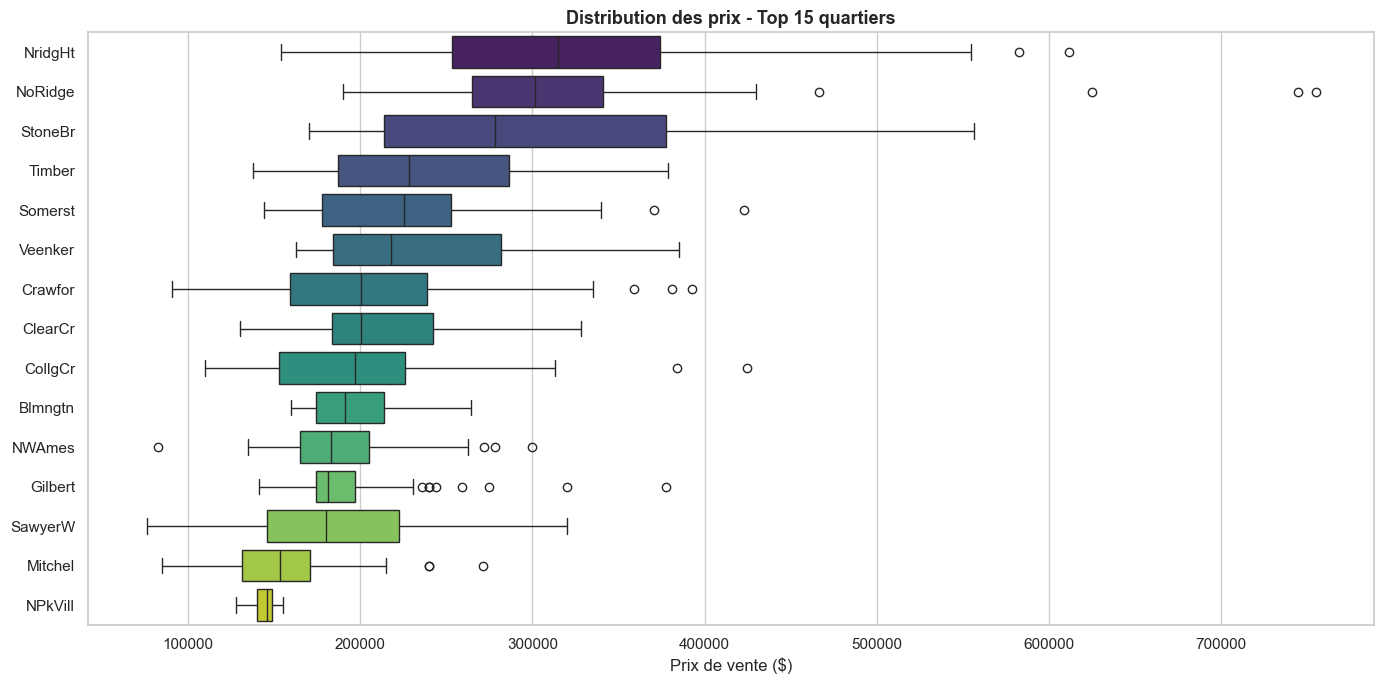

In [23]:
# Boxplot des prix par quartier (top 15)
top_neighborhoods = df.groupby('Neighborhood')['SalePrice'].median()\
                     .sort_values(ascending=False).head(15).index

fig, ax = plt.subplots(figsize=(14, 7))
sns.boxplot(data=df[df['Neighborhood'].isin(top_neighborhoods)],
            x='SalePrice', y='Neighborhood',
            order=top_neighborhoods, palette='viridis', ax=ax)
ax.set_xlabel('Prix de vente ($)')
ax.set_ylabel('')
ax.set_title('Distribution des prix - Top 15 quartiers',
             fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig(FIG_DIR / '05_price_by_neighborhood.png', bbox_inches='tight')
plt.show()

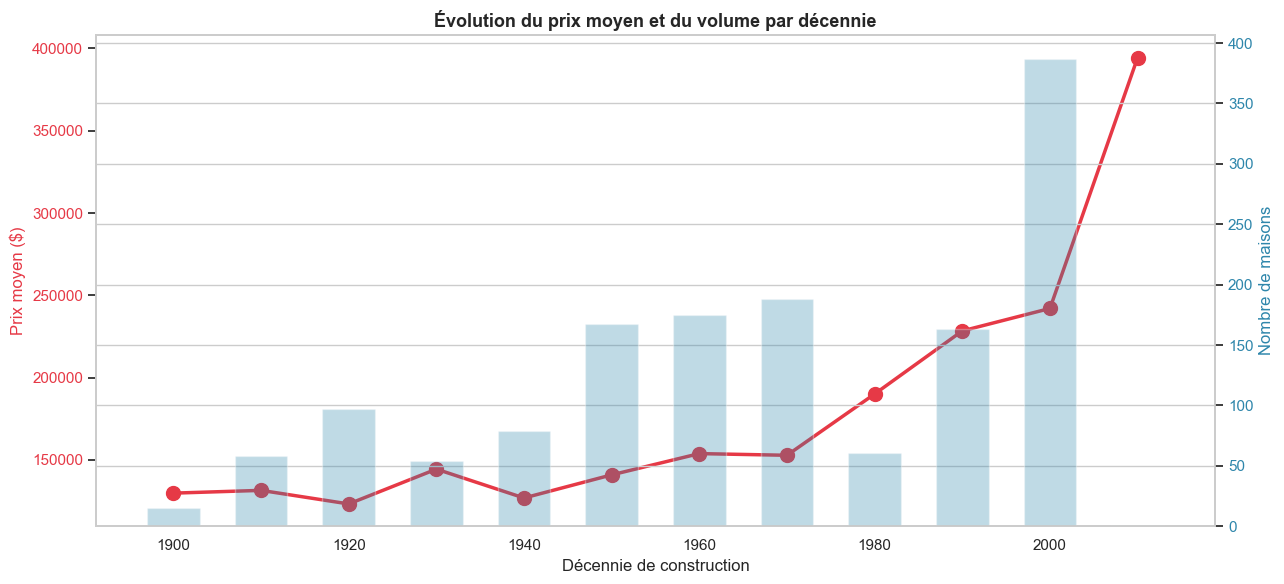

In [24]:
# Prix moyen par décennie
df['Decade'] = (df['YearBuilt'] // 10) * 10
decade_prices = df[df['YearBuilt'] >= 1900].groupby('Decade').agg(
    avg_price=('SalePrice', 'mean'),
    count=('SalePrice', 'count')
).reset_index()

fig, ax1 = plt.subplots(figsize=(13, 6))

color = '#E63946'
ax1.set_xlabel('Décennie de construction')
ax1.set_ylabel('Prix moyen ($)', color=color)
ax1.plot(decade_prices['Decade'], decade_prices['avg_price'],
         color=color, marker='o', linewidth=2.5, markersize=10)
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(False)

ax2 = ax1.twinx()
color = '#2E86AB'
ax2.set_ylabel('Nombre de maisons', color=color)
ax2.bar(decade_prices['Decade'], decade_prices['count'],
        color=color, alpha=0.3, width=6)
ax2.tick_params(axis='y', labelcolor=color)

ax1.set_title('Évolution du prix moyen et du volume par décennie',
              fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig(FIG_DIR / '06_evolution_decade.png', bbox_inches='tight')
plt.show()

## 💡 Insights clés

### 1. Corrélations majeures avec le prix
- **OverallQual** : corrélation ~0.79 → facteur #1
- **GrLivArea / TotalSF** : corrélation ~0.71 → la surface compte
- **GarageArea / GarageCars** : ~0.62 → le garage ajoute de la valeur

### 2. Distribution
- Prix fortement asymétrique à droite (skew > 0)
- **Médiane** < **Moyenne** → présence de biens très haut de gamme

### 3. Localisation
- Écart de **×2,3** entre le quartier le moins cher et le plus cher
- Les quartiers NoRidge, NridgHt, StoneBr dominent largement

### 4. Temporel
- Les constructions récentes (>2000) valent 2,8× plus que celles de 1900
- Tendance croissante nette depuis 1980

### 5. Features dérivées utiles
- **TotalSF** (surface totale) : très bonne feature
- **HouseAge** : corrélé négativement au prix
- **TotalBath** : bonne feature composite

### 🎯 Recommandations pour le modèle ML
1. Utiliser **OverallQual**, **GrLivArea**, **TotalSF**, **GarageArea** comme features principales
2. Encoder les quartiers en **target encoding** ou **one-hot**
3. Appliquer une transformation **log** sur SalePrice (distribution asymétrique)
4. Tester **Ridge**, **Random Forest**, **XGBoost**